In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
from pathlib import Path

# Ruta relativa al repositorio (los notebooks se ejecutan desde notebooks/)
DATA_PATH = Path("..") / "data" / "rendimiento_estudiantes.csv"
# cargamos el dataset 
df = pd.read_csv(DATA_PATH, sep=";")
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [3]:
# definimos el problema de regresión

# Queremos predecir la nota media del segundo semestre
target = "nota_media_2sem"

# Eliminamos el target y las variables del segundo semestre que producirían fuga de información.
# También eliminamos la variable objetivo final del estudiante, ya que incorpora información
# demasiado cercana al desenlace académico y contaminaría la predicción.
columnas_a_eliminar = [
    "nota_media_2sem",
    "asignaturas_2sem_aprobadas",
    "asignaturas_2sem_evaluadas",
    "asignaturas_2sem_matriculadas",
    "asignaturas_2sem_convalidadas",
    "asignaturas_2sem_sin_evaluacion",
    "objetivo"
]

X_df = df.drop(columns=columnas_a_eliminar)
y = df[target].values

print("Shape de X:", X_df.shape)
print("Shape de y:", y.shape)

Shape de X: (4424, 30)
Shape de y: (4424,)


### Definición del problema de regresión

En esta tarea se busca predecir `nota_media_2sem`, es decir, la calificación media obtenida en el segundo semestre. Para que el problema esté bien planteado, se eliminan no solo la variable objetivo, sino también aquellas variables del segundo semestre que contienen información contemporánea o prácticamente equivalente al valor que se quiere predecir.

Además, se excluye la variable `objetivo`, ya que refleja la situación final del estudiante (abandono, matriculado o graduado) y está demasiado ligada al desenlace académico global. Mantenerla como predictor introduciría una contaminación metodológica, porque el modelo estaría utilizando información muy próxima al resultado final para estimar el rendimiento del segundo semestre.

In [4]:
# Verificamos que no quedan variables problemáticas en el conjunto de predictores

columnas_2sem_restantes = [col for col in X_df.columns if "2sem" in col]
print("Variables del segundo semestre que siguen en X:")
print(columnas_2sem_restantes)

print("\n¿Está 'objetivo' en X?")
print("objetivo" in X_df.columns)


Variables del segundo semestre que siguen en X:
[]

¿Está 'objetivo' en X?
False


In [5]:
# codificación de las variables categóricas

# Transformamos las variables categóricas a variables dummy
num_categoricas = X_df.select_dtypes(include="object").shape[1]
X_encoded = pd.get_dummies(X_df, drop_first=True)

print("Número de variables categóricas originales:", num_categoricas)
print("Shape original:", X_df.shape)
print("Shape codificado:", X_encoded.shape)

Número de variables categóricas originales: 17
Shape original: (4424, 30)
Shape codificado: (4424, 232)


### Codificación de variables categóricas

Tras la transformación one-hot, el número de columnas aumenta de forma notable. Este crecimiento es esperable en este dataset, ya que varias variables categóricas presentan muchas modalidades distintas, como el curso, la nacionalidad, la vía de acceso o la ocupación de los progenitores.

Por tanto, pasar de 31 variables originales a más de 200 columnas no es un error, sino una consecuencia natural de representar categorías nominales en formato numérico. La implicación metodológica es que aumenta la dimensionalidad del problema y, con ello, la posibilidad de colinealidad e inestabilidad en modelos lineales no regularizados.

### Separación en entrenamiento y prueba

Se reserva el 20% de los datos como conjunto de test con `random_state=42` para garantizar la reproducibilidad. A diferencia de la tarea de clasificación, aquí **no se usa `stratify`** porque la variable objetivo es continua. El argumento `stratify` solo acepta variables categóricas (discretas), ya que su función es preservar la proporción de cada clase en train y test. Para una variable numérica como `nota_media_2sem` esto no aplica; la aleatorización del split es suficiente para obtener distribuciones de train y test similares con el tamaño de muestra disponible (n=4424).


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3539, 232)
X_test: (885, 232)
y_train: (3539,)
y_test: (885,)


In [7]:
# El escalado se aplica dentro de cada Pipeline (StandardScaler -> modelo).
# Así el scaler se ajusta solo con los datos de entrenamiento de cada fold,
# evitando fuga de información en la validación cruzada.
# Los modelos basados en árboles se entrenan sin escalado.


### Escalado de variables

El escalado se aplica únicamente a los modelos lineales, ya que estos sí dependen de la magnitud relativa de los predictores. En cambio, los modelos basados en árboles realizan particiones por umbrales y no son sensibles a la escala, por lo que no requieren esta transformación.

In [8]:
# VALIDACIÓN CRUZADA EN TRAIN
# Se hace solo sobre el conjunto de entrenamiento para no contaminar el test final.

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

modelos_cv = {
    "Dummy": Pipeline([
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),
    "Decision Tree": Pipeline([
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(random_state=42))
    ])
}

resultados_cv = []

for nombre, modelo in modelos_cv.items():
    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    resultados_cv.append({
        "Modelo": nombre,
        "CV_RMSE_mean": -scores["test_rmse"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
        "CV_MAE_mean": -scores["test_mae"].mean(),
        "CV_MAE_std": scores["test_mae"].std(),
        "CV_R2_mean": scores["test_r2"].mean(),
        "CV_R2_std": scores["test_r2"].std()
    })

resultados_cv = pd.DataFrame(resultados_cv).sort_values(by="CV_RMSE_mean")
resultados_cv

,Modelo,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std,CV_R2_mean,CV_R2_std
5,Random Forest,2.477965,0.109927,1.284201,0.067224,0.770748,0.032273
2,Ridge,2.690928,0.050452,1.606903,0.032788,0.730669,0.026246
1,Linear Regression,2.697781,0.046806,1.612330,0.029861,0.729345,0.025711
3,Lasso,2.949513,0.081297,1.921143,0.069605,0.677084,0.025398
4,Decision Tree,3.305440,0.069288,1.578258,0.039163,0.593601,0.039997
0,Dummy,5.212815,0.194596,4.039088,0.118660,-0.004877,0.004241


### Validación cruzada sobre entrenamiento

La validación cruzada se utiliza para estimar la estabilidad de cada modelo antes de mirar el conjunto de test. Esto permite comparar no solo el error medio, sino también su variabilidad entre particiones.

Si un modelo obtiene una media buena pero una desviación alta, su comportamiento puede depender demasiado de la partición concreta. Por eso interesa valorar conjuntamente nivel de error y estabilidad.

In [9]:
# AJUSTE DE HIPERPARÁMETROS SOLO EN TRAIN

# Ridge
grid_ridge = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    param_grid={
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid_ridge.fit(X_train, y_train)

# Lasso
grid_lasso = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),
    param_grid={
        "model__alpha": [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid_lasso.fit(X_train, y_train)

# Árbol
grid_tree = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid={
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_leaf": [1, 2, 5, 10]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid_tree.fit(X_train, y_train)

# Random Forest
grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid={
        "n_estimators": [200],
        "max_depth": [5, 10, 20],
        "min_samples_leaf": [1, 2, 5],
        "max_features": ["sqrt", 0.5]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print("Mejor Ridge:", grid_ridge.best_params_)
print("Mejor Lasso:", grid_lasso.best_params_)
print("Mejor Árbol:", grid_tree.best_params_)
print("Mejor Random Forest:", grid_rf.best_params_)

Mejor Ridge: {'model__alpha': 100}
Mejor Lasso: {'model__alpha': 0.05}
Mejor Árbol: {'max_depth': 5, 'min_samples_leaf': 10}
Mejor Random Forest: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}


### Ajuste de hiperparámetros

Los hiperparámetros se optimizan exclusivamente sobre entrenamiento mediante validación cruzada. En los modelos regularizados, este paso permite controlar el equilibrio entre ajuste y complejidad. En los modelos basados en árboles, limita el riesgo de sobreajuste mediante restricciones sobre profundidad, número de hojas o número de variables consideradas en cada partición.

De este modo, la comparación final en test se realiza entre versiones ajustadas de cada modelo y no entre configuraciones arbitrarias.

### Baseline con Dummy Regressor

El modelo dummy predice siempre la media de la variable objetivo en entrenamiento. No pretende capturar estructura real de los datos, sino servir como referencia mínima: cualquier modelo útil debe mejorar claramente este punto de partida.

Si un modelo no supera al dummy, su complejidad no estaría justificada.

In [10]:
# BASELINE MÍNIMO: Dummy Regressor
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)

y_pred_dummy = dummy_reg.predict(X_test)

print("=== Dummy Regressor ===")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dummy)))
print("MAE:", mean_absolute_error(y_test, y_pred_dummy))
print("R2:", r2_score(y_test, y_pred_dummy))

=== Dummy Regressor ===
RMSE: 5.203278566628959
MAE: 4.022475154380694
R2: -6.055866336618365e-06


In [11]:
# 1. REGRESIÓN LINEAL

lin_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print("=== Linear Regression ===")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lin)))
print("MAE:", mean_absolute_error(y_test, y_pred_lin))
print("R2:", r2_score(y_test, y_pred_lin))

=== Linear Regression ===
RMSE: 2.6814453396665465
MAE: 1.6169108172379871
R2: 0.7344255000320599


### Regresión lineal sin regularización

La regresión lineal ordinaria produce resultados numéricamente inestables, con errores desproporcionados y un R² muy negativo. Esto indica que el modelo no está capturando señal útil, sino amplificando problemas de colinealidad y redundancia entre predictores.

La causa es coherente con la estructura del dataset: tras la codificación one-hot, el número de variables crece mucho y aparecen dependencias fuertes entre columnas. En este contexto, los modelos lineales sin regularización se vuelven especialmente frágiles, por lo que su mal rendimiento no invalida el problema, sino que justifica el uso de regularización.

#### Nota de reproducibilidad: diagnóstico de la matriz de diseño

La causa concreta de la inestabilidad es que la matriz de predictores (tras one-hot y escalado) **no tiene rango completo**: hay columnas sin varianza en el conjunto de entrenamiento y combinaciones lineales exactas entre dummies. Por tanto, el problema de mínimos cuadrados ordinarios **no tiene solución única**.

Cuando la solución no es única, el resultado depende de la rutina numérica (LAPACK/BLAS) que use cada instalación. En la ejecución original (Windows) los coeficientes se dispararon (RMSE ≈ 10¹³); en otras plataformas, como Linux, se obtiene la solución de norma mínima y un R² ≈ 0.73. En ambos casos la conclusión es la misma: **la regresión lineal sin regularizar está mal planteada en este espacio de variables**, y Ridge y Lasso la resuelven de forma estable en cualquier plataforma.

In [12]:
# Diagnóstico: rango y varianza de la matriz de diseño escalada (solo train)
X_train_scaled_diag = StandardScaler().fit_transform(X_train.astype(float))

print("Columnas:", X_train_scaled_diag.shape[1])
print("Rango:   ", np.linalg.matrix_rank(X_train_scaled_diag))
print("Columnas sin varianza en train:", int((X_train.astype(float).std() == 0).sum()))

Columnas: 232
Rango:    221
Columnas sin varianza en train: 6


In [13]:
# 2. RIDGE

ridge = grid_ridge.best_estimator_

ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

print("=== Ridge Regression ===")
print("Best params:", grid_ridge.best_params_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("R2:", r2_score(y_test, y_pred_ridge))

=== Ridge Regression ===
Best params: {'model__alpha': 100}
RMSE: 2.6743234860754477
MAE: 1.6057225930990913
R2: 0.7358343454372827


### Ridge

Ridge estabiliza la regresión penalizando coeficientes grandes. Su mejora drástica frente a la regresión lineal sin regularizar confirma que el problema no era la ausencia de relación lineal, sino la inestabilidad del ajuste ante un espacio de predictores amplio y correlacionado.

Por tanto, la regularización L2 resulta útil cuando muchas variables contienen señal parcial pero redundante.

In [14]:
# 3. LASSO

lasso = grid_lasso.best_estimator_

lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)

print("=== Lasso Regression ===")
print("Best params:", grid_lasso.best_params_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("R2:", r2_score(y_test, y_pred_lasso))

=== Lasso Regression ===
Best params: {'model__alpha': 0.05}
RMSE: 2.6373421321199855
MAE: 1.5057901854062532
R2: 0.7430897562909226


### Lasso

Lasso introduce regularización L1, lo que además de estabilizar el ajuste favorece soluciones más parsimoniosas. En este problema obtiene uno de los mejores resultados globales, lo que sugiere que no todas las variables aportan información con la misma intensidad y que una cierta selección implícita de predictores beneficia la generalización.

Su interés no es solo predictivo, sino también interpretativo, ya que permite identificar con más claridad qué variables concentran la mayor parte de la señal.

In [15]:
# 4. ÁRBOL DE REGRESIÓN

tree_reg = grid_tree.best_estimator_
tree_reg.fit(X_train, y_train)

y_pred_tree = tree_reg.predict(X_test)

print("=== Decision Tree Regressor ===")
print("Best params:", grid_tree.best_params_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_tree)))
print("MAE:", mean_absolute_error(y_test, y_pred_tree))
print("R2:", r2_score(y_test, y_pred_tree))

=== Decision Tree Regressor ===
Best params: {'max_depth': 5, 'min_samples_leaf': 10}
RMSE: 2.775277856320951
MAE: 1.4390639393243734
R2: 0.7155136609469765


### Árbol de regresión

El árbol de regresión ofrece una alternativa no lineal e interpretable. Su rendimiento es competitivo, aunque algo inferior al de los modelos regularizados y al ensamblado final. Esto sugiere que existen relaciones no lineales y posibles interacciones, pero que un único árbol no logra capturar toda la complejidad sin perder capacidad de generalización.

In [16]:
# 5. RANDOM FOREST REGRESSOR

rf_reg = grid_rf.best_estimator_
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

print("=== Random Forest Regressor ===")
print("Best params:", grid_rf.best_params_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("R2:", r2_score(y_test, y_pred_rf))

=== Random Forest Regressor ===
Best params: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}
RMSE: 2.666895480137567
MAE: 1.3927384118256705
R2: 0.7372997620150804


### Random Forest

Random Forest mejora la capacidad del árbol individual al promediar múltiples particiones. Su buen rendimiento indica que parte de la estructura del problema no es estrictamente lineal y que el uso de un ensamblado permite captar patrones más complejos sin disparar la varianza.

Además, obtener un MAE especialmente bajo sugiere que el modelo comete errores moderados de forma bastante consistente, aunque no siempre minimice tanto como otros modelos los errores más grandes.

In [17]:
# COMPARACIÓN FINAL DE MODELOS

resultados_test = pd.DataFrame({
    "Modelo": [
        "Dummy",
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Decision Tree",
        "Random Forest"
    ],
    "Test_RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_dummy)),
        np.sqrt(mean_squared_error(y_test, y_pred_lin)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
        np.sqrt(mean_squared_error(y_test, y_pred_tree)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "Test_MAE": [
        mean_absolute_error(y_test, y_pred_dummy),
        mean_absolute_error(y_test, y_pred_lin),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso),
        mean_absolute_error(y_test, y_pred_tree),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "Test_R2": [
        r2_score(y_test, y_pred_dummy),
        r2_score(y_test, y_pred_lin),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_tree),
        r2_score(y_test, y_pred_rf)
    ]
})

comparacion_final = resultados_cv.merge(resultados_test, on="Modelo", how="left")
comparacion_final.sort_values(by="CV_RMSE_mean")

,Modelo,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std,CV_R2_mean,CV_R2_std,Test_RMSE,Test_MAE,Test_R2
0,Random Forest,2.477965,0.109927,1.284201,0.067224,0.770748,0.032273,2.666895,1.392738,0.737300
1,Ridge,2.690928,0.050452,1.606903,0.032788,0.730669,0.026246,2.674323,1.605723,0.735834
2,Linear Regression,2.697781,0.046806,1.612330,0.029861,0.729345,0.025711,2.681445,1.616911,0.734426
3,Lasso,2.949513,0.081297,1.921143,0.069605,0.677084,0.025398,2.637342,1.505790,0.743090
4,Decision Tree,3.305440,0.069288,1.578258,0.039163,0.593601,0.039997,2.775278,1.439064,0.715514
5,Dummy,5.212815,0.194596,4.039088,0.118660,-0.004877,0.004241,5.203279,4.022475,-0.000006


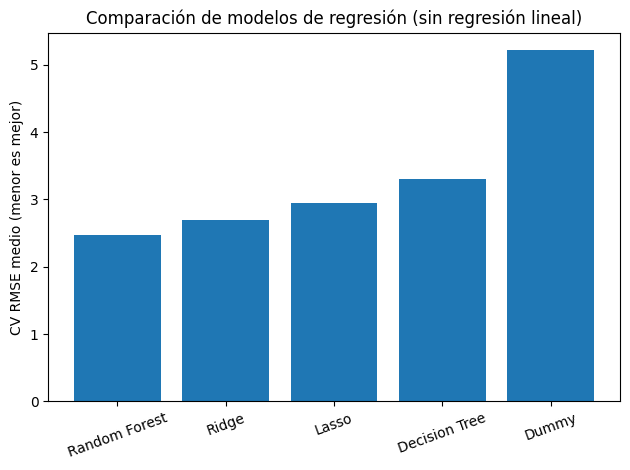

In [18]:
comparacion_plot_filtrado = comparacion_final[
    comparacion_final["Modelo"] != "Linear Regression"
]

plt.figure()

plt.bar(
    comparacion_plot_filtrado["Modelo"],
    comparacion_plot_filtrado["CV_RMSE_mean"]
)

plt.ylabel("CV RMSE medio (menor es mejor)")
plt.xticks(rotation=20)
plt.title("Comparación de modelos de regresión (sin regresión lineal)")

plt.tight_layout()
plt.show()

### Comparación global de modelos

La comparación final muestra tres ideas claras. Primero, todos los modelos razonables superan ampliamente al dummy, por lo que existe señal predictiva real en las variables previas y del primer semestre. Segundo, la regresión lineal sin regularización queda descartada por su inestabilidad. Tercero, los mejores resultados se concentran en Lasso, Ridge y Random Forest, lo que sugiere que el problema combina una parte importante de estructura aproximadamente lineal con efectos adicionales que los modelos no lineales también son capaces de aprovechar.

No aparece, por tanto, un ganador absoluto en todas las métricas: Lasso destaca en RMSE y R², mientras que Random Forest presenta un MAE especialmente competitivo.

nota_media_1sem                                           2.813616
asignaturas_1sem_aprobadas                                2.080164
asignaturas_1sem_convalidadas                            -0.604867
asignaturas_1sem_matriculadas                            -0.417866
curso_animacion_y_diseno_multimedia                      -0.359220
matricula_al_dia_si                                       0.271881
curso_ingenieria_informatica                              0.187285
cualificacion_padre_curso_tecnico_profesional            -0.146134
tasa_desempleo                                           -0.118698
cualificacion_madre_desconocido                          -0.118056
cualificacion_padre_curso_complementario_de_secundaria   -0.116483
modo_solicitud_cambio_de_curso                            0.107892
nacionalidad_mozambiquena                                -0.106711
cualificacion_padre_frecuencia_de_educacion_superior     -0.106431
curso_gestion_nocturno                                    0.10

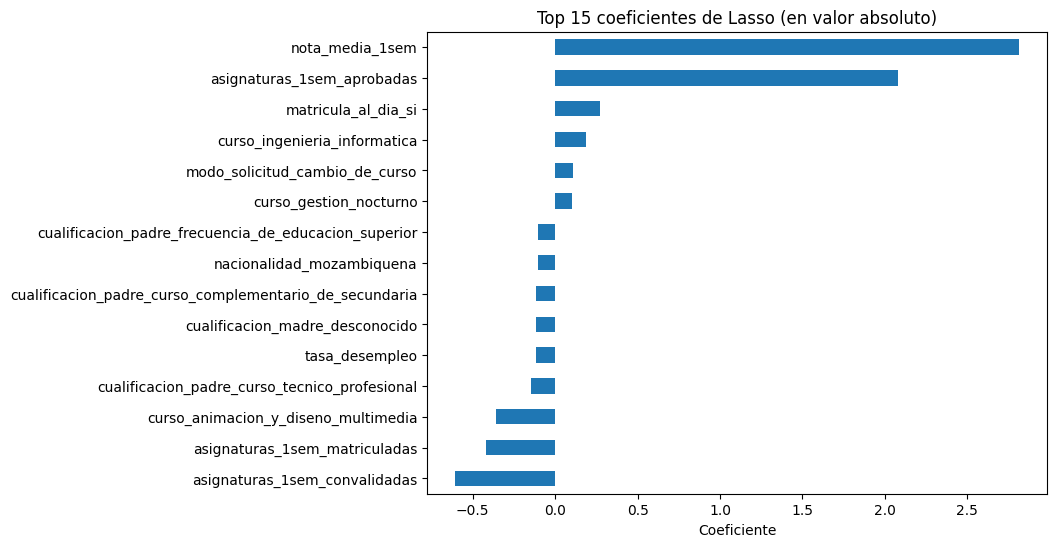

In [19]:
# VARIABLES MÁS IMPORTANTES EN LASSO

coef_lasso = pd.Series(
    lasso.named_steps["model"].coef_,
    index=X_train.columns
).sort_values(key=np.abs, ascending=False)

print(coef_lasso.head(15))

plt.figure(figsize=(8, 6))
coef_lasso.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 coeficientes de Lasso (en valor absoluto)")
plt.xlabel("Coeficiente")
plt.show()

### Variables más relevantes según Lasso

Los coeficientes de mayor magnitud permiten identificar qué variables están más asociadas a la predicción de la nota del segundo semestre dentro de un modelo lineal regularizado. En general, cabe esperar un peso destacado de las variables de rendimiento del primer semestre, lo que sería coherente con la idea de continuidad académica: el desempeño inicial condiciona de forma importante el rendimiento posterior.

La interpretación debe hacerse con prudencia, ya que el signo y magnitud de los coeficientes dependen del resto de variables presentes en el modelo.

asignaturas_1sem_aprobadas             0.428616
nota_media_1sem                        0.279521
asignaturas_1sem_evaluadas             0.097827
asignaturas_1sem_matriculadas          0.022051
nota_admision                          0.015838
edad_al_matricularse                   0.012135
nota_cualificacion_previa              0.010556
matricula_al_dia_si                    0.010169
tasa_desempleo                         0.007439
tasa_inflacion                         0.006765
pib                                    0.005578
curso_animacion_y_diseno_multimedia    0.005052
modo_solicitud_cambio_de_curso         0.004127
orden_solicitud                        0.003435
curso_ingenieria_informatica           0.003179
dtype: float64


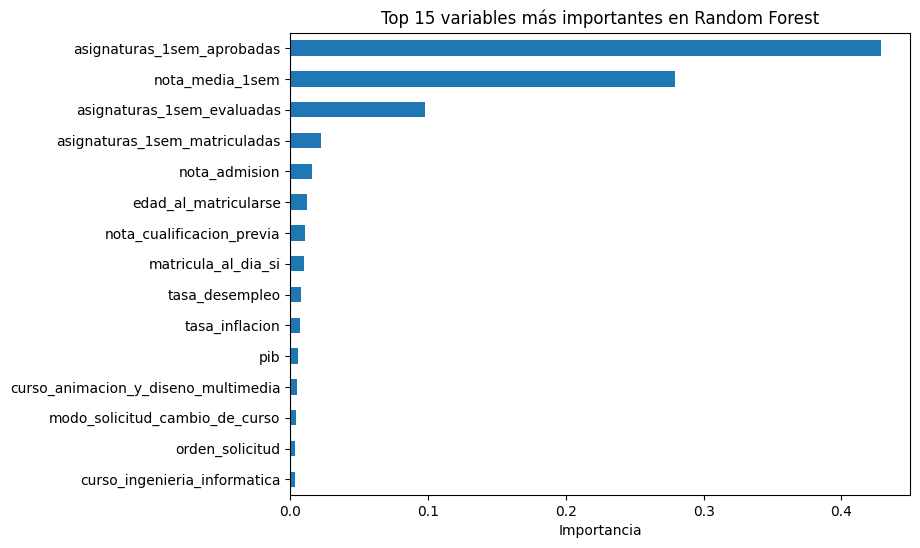

In [20]:
# IMPORTANCIA DE VARIABLES EN RANDOM FOREST

importancias_rf = pd.Series(
    rf_reg.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importancias_rf.head(15))
plt.figure(figsize=(8, 6))
importancias_rf.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 variables más importantes en Random Forest")
plt.xlabel("Importancia")
plt.show()

### Importancia de variables en Random Forest

La importancia de variables en Random Forest permite detectar qué predictores provocan una mayor degradación del rendimiento cuando se alteran. Esto complementa la lectura de Lasso, ya que aquí no se asume linealidad y pueden emerger interacciones o relaciones no aditivas.

Si las variables del primer semestre vuelven a aparecer entre las más influyentes, ello refuerza la consistencia del análisis: distintos enfoques estarían señalando una misma fuente principal de información predictiva.

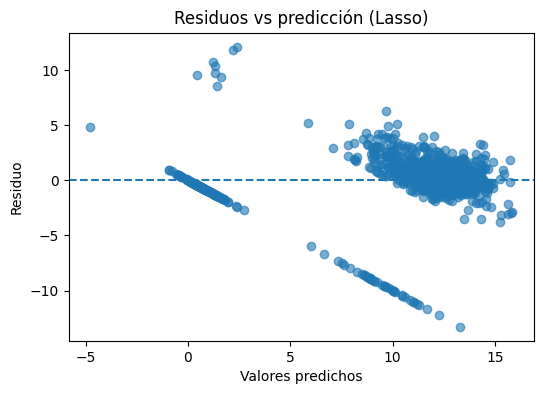

In [21]:
# ANÁLISIS DE RESIDUOS DEL MEJOR MODELO EN RMSE/R2 (LASSO)

residuos = y_test - y_pred_lasso

plt.figure(figsize=(6, 4))
plt.scatter(y_pred_lasso, residuos, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuo")
plt.title("Residuos vs predicción (Lasso)")
plt.show()

### Análisis de residuos

El gráfico de residuos muestra un comportamiento globalmente adecuado, con una nube principal de puntos centrada en torno a cero, lo que indica que el modelo no presenta un sesgo sistemático claro en la mayoría de las predicciones.

Sin embargo, aparecen dos patrones relevantes que permiten profundizar en la interpretación. En primer lugar, se observa una banda diagonal descendente correspondiente a observaciones cuya nota real es cero. En estos casos, el residuo coincide con el valor negativo de la predicción, lo que genera una estructura lineal característica. Este patrón no indica un fallo del modelo, sino una particularidad del dataset, que presenta una acumulación significativa de valores nulos en la variable objetivo.

En segundo lugar, la dispersión de los residuos no es completamente homogénea: mientras que en el rango central de predicciones los errores son relativamente pequeños y simétricos, en los extremos aparecen errores más pronunciados. Esto sugiere que el modelo captura correctamente el comportamiento medio de los estudiantes, pero encuentra mayor dificultad en aquellos casos más atípicos o extremos.

En conjunto, el análisis de residuos confirma que el modelo ofrece un ajuste razonable, aunque pone de manifiesto la existencia de heterogeneidad en el error y la influencia de la distribución de la variable objetivo en la forma de los residuos.

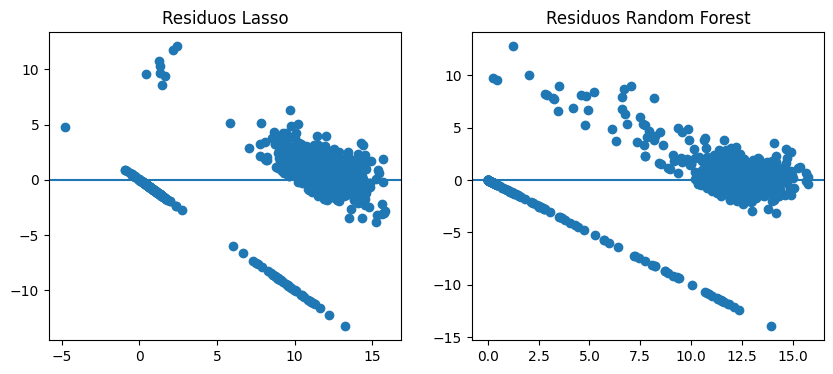

In [22]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.scatter(y_pred_lasso, y_test - y_pred_lasso)
plt.title("Residuos Lasso")
plt.axhline(0)

plt.subplot(1,2,2)
plt.scatter(y_pred_rf, y_test - y_pred_rf)
plt.title("Residuos Random Forest")
plt.axhline(0)

plt.show()

### Análisis de residuos: Lasso vs Random Forest

El análisis de residuos permite evaluar la calidad del ajuste de los modelos y detectar posibles patrones no capturados.

En ambos modelos se observan patrones estructurados en los residuos, lo que indica que no se cumple completamente la hipótesis de errores aleatorios:

- En Lasso, los residuos muestran una clara estructura lineal y agrupaciones, lo que sugiere que el modelo no está capturando adecuadamente relaciones no lineales presentes en los datos.
- En Random Forest, aunque también aparecen patrones, los residuos están más concentrados alrededor de cero, indicando un mejor ajuste global.

Además, se identifican bandas diagonales en ambos gráficos, lo que sugiere la existencia de valores discretos en la variable objetivo o grupos de comportamiento diferenciados en los datos.

Comparativamente:

- Random Forest presenta residuos más centrados y menor dispersión.
- Lasso presenta mayor sesgo estructural, típico de modelos lineales cuando la relación real es compleja.

En consecuencia, aunque Lasso es más interpretable, Random Forest captura mejor la estructura de los datos, lo que explica su mejor rendimiento en métricas como MAE.

Este análisis refuerza la idea de que el problema presenta cierta no linealidad que los modelos basados en árboles son capaces de modelizar con mayor eficacia.

### Observación general

Los resultados muestran que la información previa del estudiante y, sobre todo, su rendimiento en el primer semestre permiten anticipar con bastante precisión la nota media del segundo semestre. La mejora respecto al dummy es muy amplia en todos los modelos competitivos, lo que confirma que el problema contiene señal predictiva real.

La comparación entre modelos también revela que la regularización es clave. La regresión lineal ordinaria fracasa por inestabilidad numérica, mientras que Ridge y Lasso corrigen este problema y logran un rendimiento alto. Random Forest también ofrece resultados sólidos, lo que sugiere que, junto a una estructura aproximadamente lineal, existen patrones adicionales de carácter no lineal.

# Conclusión

En esta tarea de regresión se ha intentado predecir `nota_media_2sem` utilizando únicamente información disponible antes de conocer el rendimiento agregado del segundo semestre. Para ello se eliminaron las variables que podían introducir fuga de información, de modo que la evaluación reflejara una situación predictiva metodológicamente correcta.

Los resultados obtenidos indican que el rendimiento previo del estudiante, especialmente el correspondiente al primer semestre, concentra una parte muy importante de la capacidad predictiva del problema. Esto sugiere que el desempeño académico inicial no solo describe el presente del alumno, sino que anticipa de manera bastante directa su evolución a corto plazo.

Desde el punto de vista de modelización, la comparación muestra que los mejores resultados se obtienen con modelos regularizados y con Random Forest. Lasso destaca por su equilibrio entre precisión e interpretabilidad, mientras que Random Forest ofrece un comportamiento especialmente competitivo en error absoluto medio. En cambio, la regresión lineal sin regularización queda descartada por la fuerte inestabilidad derivada de la alta dimensionalidad y la colinealidad introducidas tras la codificación de variables categóricas.

En conjunto, la regresión confirma que es posible anticipar de forma razonable el rendimiento del segundo semestre a partir de información previa, siempre que el problema se formule con cuidado y se controle la contaminación entre predictores y variable objetivo.